# OASIS INFOBYTE — DATA SCIENCE INTERNSHIP

## Task 1: Iris Flower Classification

### Objective
Build and evaluate machine learning classification models to predict iris flower species from their physical measurements.

### Tools and Libraries
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn.

### Project Workflow
1. Dataset loading and inspection
2. Exploratory Data Analysis (EDA)
3. Data visualization
4. Feature selection discussion
5. Train-test splitting
6. Training two or more classification models
7. Model evaluation and comparison
8. Best-model selection and conclusion

In [1]:



import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:
iris = load_iris()
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["species"] = iris.target
df["species"] = df["species"].map(
    dict(enumerate(iris.target_names))
)
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSpecies counts:")
print(df["species"].value_counts())


Dataset shape: (150, 5)

Column names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']

Data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species               object
dtype: object

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Duplicate rows: 1

Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:

df.describe()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [5]:

numeric_df = df.select_dtypes(include=np.number)

stats = pd.DataFrame({
    "Mean": numeric_df.mean(),
    "Median": numeric_df.median(),
    "Mode": numeric_df.mode().iloc[0],
    "Standard Deviation": numeric_df.std()
})

stats


,Mean,Median,Mode,Standard Deviation
sepal length (cm),5.843333,5.80,5.0,0.828066
sepal width (cm),3.057333,3.00,3.0,0.435866
petal length (cm),3.758000,4.35,1.4,1.765298
petal width (cm),1.199333,1.30,0.2,0.762238


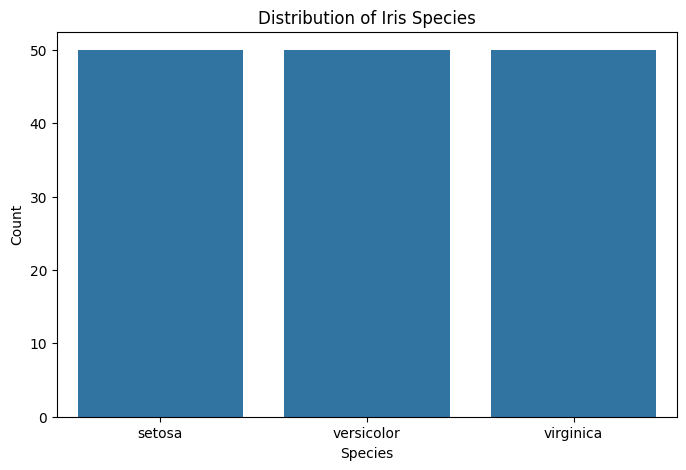

In [6]:

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="species")
plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.show()


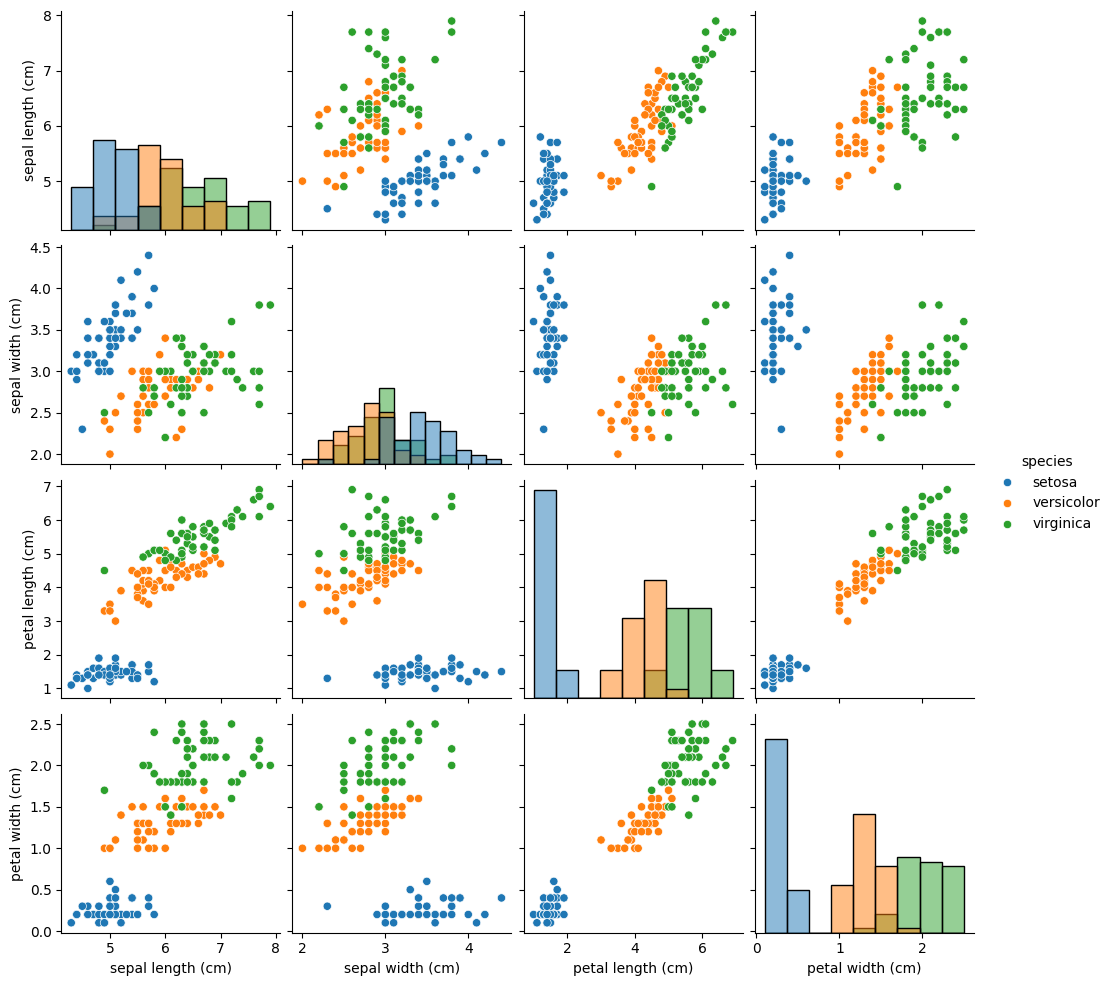

In [7]:

sns.pairplot(df, hue="species", diag_kind="hist")
plt.show()


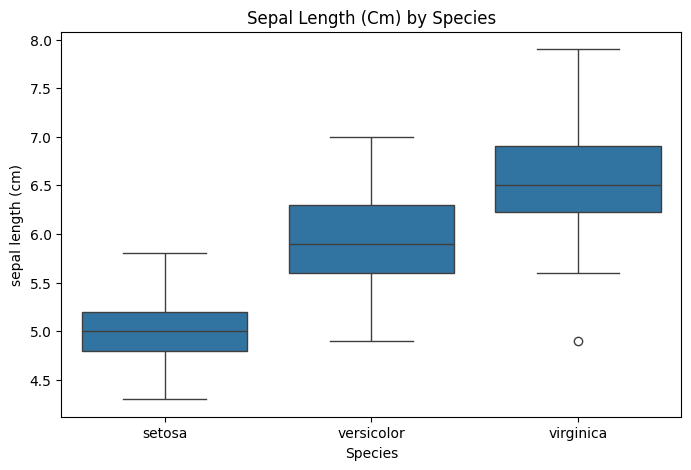

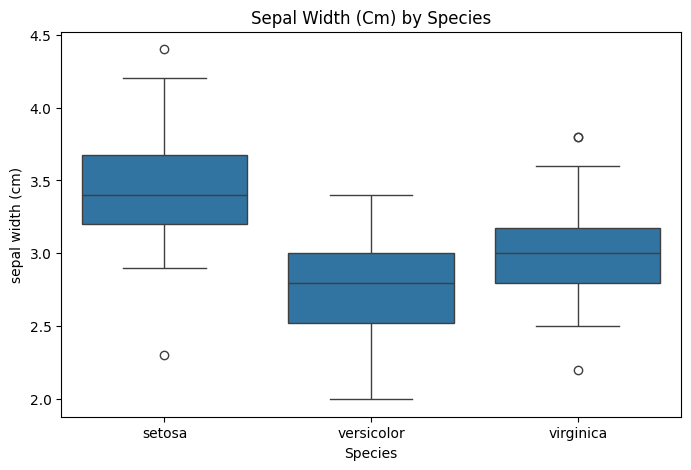

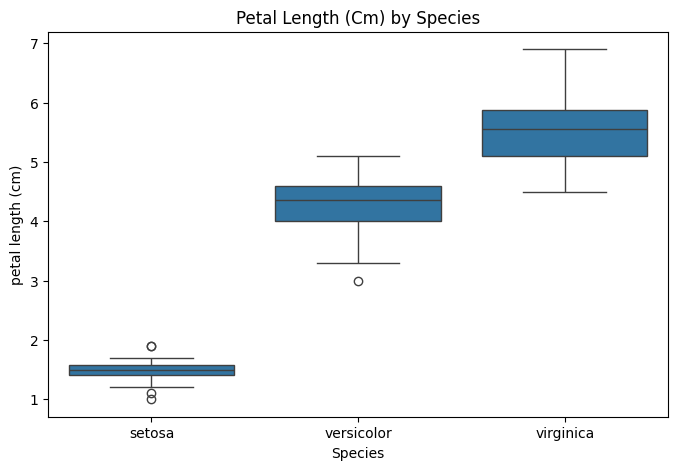

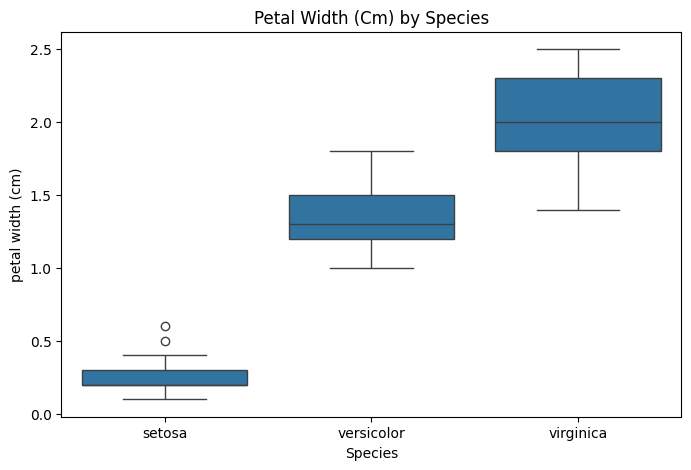

In [8]:

features = iris.feature_names

for feature in features:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x="species", y=feature)
    plt.title(f"{feature.title()} by Species")
    plt.xlabel("Species")
    plt.ylabel(feature)
    plt.show()


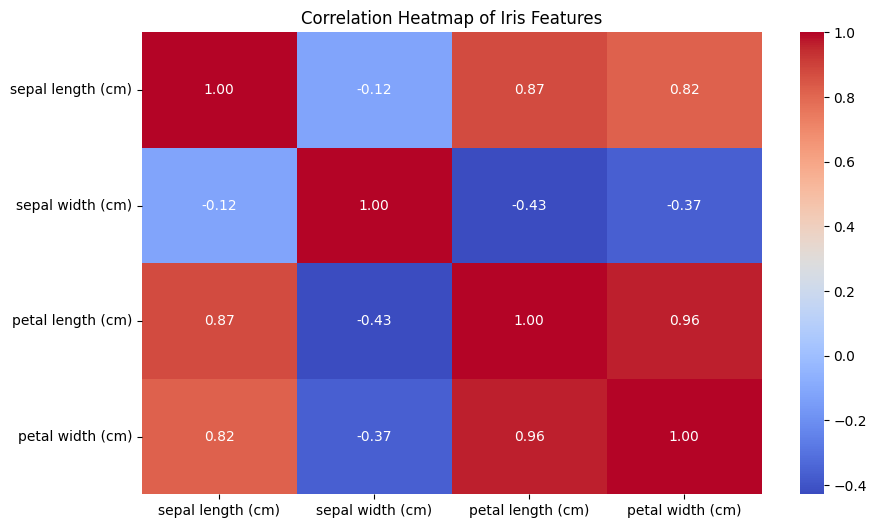

In [9]:

plt.figure(figsize=(10, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap of Iris Features")
plt.show()


### Feature Selection

Petal length and petal width are expected to be highly useful features for distinguishing the three iris species. Sepal measurements may also contribute to classification, but their discriminative power can differ. The correlation heatmap helps identify relationships between numerical features.

In [10]:

X = df.drop("species", axis=1)
y = iris.target

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (150, 4)
Target shape: (150,)


In [11]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 120
Testing samples: 30


In [12]:

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

log_model = LogisticRegression(max_iter=200)
knn_model = KNeighborsClassifier(n_neighbors=5)

log_model.fit(X_train, y_train)
knn_model.fit(X_train, y_train)

print("Both models trained successfully.")


Both models trained successfully.


In [14]:

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

log_pred = log_model.predict(X_test)
knn_pred = knn_model.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, log_pred))
print("\nKNN Accuracy:", accuracy_score(y_test, knn_pred))

print("\nLogistic Regression Classification Report:")
print(classification_report(y_test, log_pred, target_names=iris.target_names))

print("\nKNN Classification Report:")
print(classification_report(y_test, knn_pred, target_names=iris.target_names))


Logistic Regression Accuracy: 0.9666666666666667

KNN Accuracy: 1.0

Logistic Regression Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


KNN Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



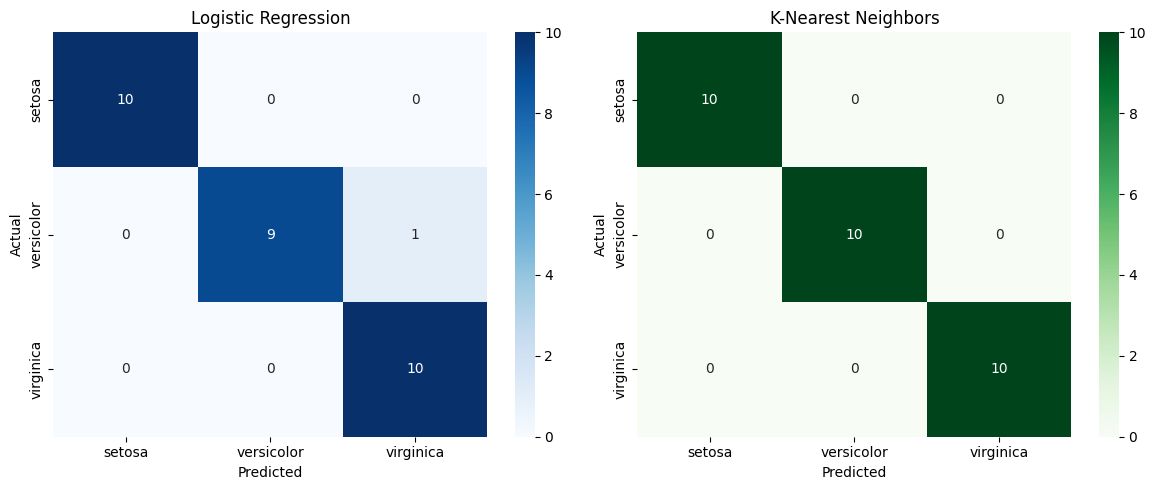

In [15]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_test, log_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names,
    ax=axes[0]
)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(y_test, knn_pred),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names,
    ax=axes[1]
)
axes[1].set_title("K-Nearest Neighbors")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


In [16]:

results = pd.DataFrame({
    "Model": ["Logistic Regression", "K-Nearest Neighbors"],
    "Accuracy": [
        accuracy_score(y_test, log_pred),
        accuracy_score(y_test, knn_pred)
    ]
})

results = results.sort_values(by="Accuracy", ascending=False)
results


,Model,Accuracy
1,K-Nearest Neighbors,1.000000
0,Logistic Regression,0.966667


In [17]:

best_model_name = results.iloc[0]["Model"]

if best_model_name == "Logistic Regression":
    best_model = log_model
else:
    best_model = knn_model

print("Best model:", best_model_name)
print("Best test accuracy:", round(results.iloc[0]["Accuracy"], 4))


Best model: K-Nearest Neighbors
Best test accuracy: 1.0


In [18]:

sample = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

prediction = best_model.predict(sample)[0]

print("Predicted Iris species:", iris.target_names[prediction])


Predicted Iris species: setosa


## Conclusion

The Iris Flower Classification project explored the Iris dataset and applied machine learning techniques to classify flowers into Setosa, Versicolor, and Virginica species.

Exploratory Data Analysis helped identify patterns and relationships among sepal and petal measurements. The correlation heatmap and visualizations provided insights into which features may be most useful for distinguishing species.

Two classification algorithms, Logistic Regression and K-Nearest Neighbors, were trained and evaluated using accuracy, precision, recall, F1-score, and confusion matrices. The best-performing model was selected based on its test-set accuracy.

This project demonstrates how data visualization, feature analysis, and supervised machine learning can be combined to solve a classification problem.

## Project Summary

- **Internship:** Oasis Infobyte
- **Track:** Data Science
- **Task:** Iris Flower Classification
- **Dataset:** Built-in Iris dataset from Scikit-learn
- **Models:** Logistic Regression and K-Nearest Neighbors
- **Evaluation:** Accuracy, classification report, and confusion matrix
- **Environment:** Google Colab